# Kernel-based finite-temperature crossover diagram from IPR features

This notebook constructs a finite-temperature crossover diagnostic for the 1D transverse-field Ising model using the normalized IPR contrast

$$C_{\mathrm{IPR}}(h,\beta)=\frac{\mathrm{IPR}_Z(h,\beta)-\mathrm{IPR}_X(h,\beta)}{\mathrm{IPR}_Z(h,\beta)+\mathrm{IPR}_X(h,\beta)}.$$

The plot is a quantum-critical fan analogue and should be interpreted as a crossover diagram, not as evidence for a true finite-temperature phase transition.

In [19]:
from __future__ import annotations

from pathlib import Path
import sys

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
import numpy as np
import pandas as pd

def find_repo_root(start: Path | None = None) -> Path:
    """Find the project root so notebook imports work from any working directory."""
    start = Path.cwd() if start is None else Path(start).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "scripts" / "data_config.py").is_file():
            return candidate
    raise FileNotFoundError("Could not find repository root containing scripts/data_config.py.")


REPO_ROOT = find_repo_root()
SCRIPTS_DIR = REPO_ROOT / "scripts"
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

from data_config import read_thermal_ipr_data, thermal_ipr_path
from plot_ipr_curves import CURVE_STYLES, set_ipr_plot_style

IPR_CONTRAST_CMAP = LinearSegmentedColormap.from_list(
    "ipr_green_white_orange",
    [CURVE_STYLES["IPR X"]["color"], "#ffffff", CURVE_STYLES["IPR Z"]["color"]],
    N=512,
)

set_ipr_plot_style()
plt.rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.spines.top": False,
    "axes.spines.right": False,
})


def annotate_panel_upper_right(ax: plt.Axes, label: str, fontsize: int = 11) -> None:
    """Place an in-panel label using the Gram-matrix annotation style."""
    ax.text(
        0.96,
        0.92,
        label,
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=fontsize,
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.72, "pad": 1.5},
    )

## Current plots
 
 The notebook now makes two beta-axis crossover diagnostics from the raw TFIM thermal IPR data. Each panel corresponds to one system size `L`, with `h` on the horizontal axis and inverse temperature `beta` on the vertical axis. The beta axis is inverted so lower temperature, larger `beta`, appears at the top.
 
 The first figure uses the normalized raw IPR contrast
 
 $$C_{\mathrm{raw}}(h,\beta)=\frac{\mathrm{IPR}_Z-\mathrm{IPR}_X}{|\mathrm{IPR}_Z|+|\mathrm{IPR}_X|}.$$
 
 The second figure uses the normalized base-10 log contrast
 
 $$C_{\log}(h,\beta)=\frac{\log_{10}(\mathrm{IPR}_Z)-\log_{10}(\mathrm{IPR}_X)}{|\log_{10}(\mathrm{IPR}_Z)|+|\log_{10}(\mathrm{IPR}_X)|}.$$
 
 Orange means the Z-basis IPR is larger, while green means the X-basis IPR is larger. The white contour marks zero contrast, where the two basis diagnostics agree. The black dashed curve is the guide `T = |h-h_c|`, shown on the beta axis as `beta = 1 / |h-h_c|` with `h_c = 1`. This remains a finite-temperature crossover diagnostic, not a true finite-temperature phase-transition plot.

In [20]:
def load_tfim_thermal_ipr(L: int = 20, source: str = "processed") -> pd.DataFrame:
    """Load TFIM thermal IPR data through scripts/data_config.py and validate columns."""
    path = thermal_ipr_path(L=L, source=source)
    df = read_thermal_ipr_data(L=L, source=source)
    required = {"h", "beta", "ipr_z", "ipr_x"}
    missing = required.difference(df.columns)
    if missing:
        raise ValueError(f"{path.name} is missing required columns: {sorted(missing)}")

    df = df.copy()
    for column in required:
        df[column] = pd.to_numeric(df[column], errors="coerce")
    return df.dropna(subset=list(required))


CONTRAST_LABELS = {
    "raw": r"$(\mathrm{IPR}_Z - \mathrm{IPR}_X) / (|\mathrm{IPR}_Z| + |\mathrm{IPR}_X|)$",
    "log": r"$[\log_{10}(\mathrm{IPR}_Z) - \log_{10}(\mathrm{IPR}_X)] / [|\log_{10}(\mathrm{IPR}_Z)| + |\log_{10}(\mathrm{IPR}_X)|]$",
}


def compute_ipr_contrast_grid(df: pd.DataFrame, contrast: str = "raw") -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Compute an IPR contrast and return regular h, beta, contrast arrays.

    The input can be a long dataframe. beta = 0 is excluded from the crossover plot.
    Duplicate (beta, h) pairs are treated as an input error rather than averaged.
    """
    contrast = contrast.lower().strip()
    if contrast not in CONTRAST_LABELS:
        raise ValueError(f"contrast must be one of {list(CONTRAST_LABELS)}")

    data = df.loc[df["beta"] > 0, ["h", "beta", "ipr_z", "ipr_x"]].copy()
    if data.empty:
        raise ValueError("No rows remain after excluding beta <= 0.")

    if contrast == "raw":
        denominator = np.abs(data["ipr_z"]) + np.abs(data["ipr_x"])
        data = data.loc[denominator != 0].copy()
        data["contrast"] = (data["ipr_z"] - data["ipr_x"]) / denominator.loc[data.index]
    elif contrast == "log":
        data = data.loc[(data["ipr_z"] > 0) & (data["ipr_x"] > 0)].copy()
        log_z = np.log10(data["ipr_z"])
        log_x = np.log10(data["ipr_x"])
        denominator = np.abs(log_z) + np.abs(log_x)
        data = data.loc[denominator != 0].copy()
        data["contrast"] = (log_z.loc[data.index] - log_x.loc[data.index]) / denominator.loc[data.index]

    duplicate_mask = data.duplicated(subset=["beta", "h"], keep=False)
    if duplicate_mask.any():
        n_duplicates = int(duplicate_mask.sum())
        raise ValueError(f"Found {n_duplicates} rows with duplicate (beta, h) coordinates; resolve duplicates before pivoting.")

    contrast_grid = data.pivot(index="beta", columns="h", values="contrast")
    contrast_grid = contrast_grid.sort_index(axis=0).sort_index(axis=1)

    h = contrast_grid.columns.to_numpy(dtype=float)
    beta = contrast_grid.index.to_numpy(dtype=float)
    order = np.argsort(beta)
    beta = beta[order]
    C = contrast_grid.to_numpy(dtype=float)[order, :]
    return h, beta, C


def draw_ipr_crossover_panel(
    h: np.ndarray,
    beta: np.ndarray,
    C: np.ndarray,
    *,
    ax: plt.Axes,
    norm: TwoSlopeNorm,
    hc: float = 1.0,
    cmap = IPR_CONTRAST_CMAP,
    annotate_regions: bool = True,
    draw_crossover_contour: bool = True,
    beta_max: float | None = None,
):
    """Draw one IPR crossover panel and return the QuadMesh."""
    mesh = ax.pcolormesh(h, beta, C, shading="nearest", cmap=cmap, norm=norm, rasterized=True)

    x_min, x_max = float(np.nanmin(h)), float(np.nanmax(h))
    y_min, y_data_max = float(np.nanmin(beta)), float(np.nanmax(beta))
    y_max = y_data_max if beta_max is None else min(float(beta_max), y_data_max)
    beta_line = np.linspace(max(y_min, 1.0 / max(x_max - hc, hc - x_min)), y_max, 300)
    if beta_line.size:
        delta_h = 1.0 / beta_line
        h_right = hc + delta_h
        h_left = hc - delta_h
        mask_right = (h_right >= x_min) & (h_right <= x_max)
        mask_left = (h_left >= x_min) & (h_left <= x_max)
        ax.plot(h_right[mask_right], beta_line[mask_right], "k--", linewidth=1.15, label=rf"$T=|h-h_c|$, $h_c={hc:g}$")
        ax.plot(h_left[mask_left], beta_line[mask_left], "k--", linewidth=1.15)

    if draw_crossover_contour and np.nanmin(C) <= 0 <= np.nanmax(C):
        ax.contour(h, beta, C, levels=[0.0], colors="white", linewidths=1.4)

    if annotate_regions:
        low_beta = y_min + 0.10 * (y_max - y_min)
        ax.text(x_min + 0.18 * (x_max - x_min), low_beta, "Z-localized\nordered-like", ha="center", va="center", color="0.1")
        ax.text(x_min + 0.78 * (x_max - x_min), low_beta, "X-localized\nparamagnetic-like", ha="center", va="center", color="0.1")

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.invert_yaxis()
    return mesh


def plot_ipr_crossover_diagram(
    h: np.ndarray,
    beta: np.ndarray,
    C: np.ndarray,
    *,
    hc: float = 1.0,
    cmap = IPR_CONTRAST_CMAP,
    annotate_regions: bool = True,
    draw_crossover_contour: bool = True,
    colorbar_label: str = CONTRAST_LABELS["raw"],
    beta_max: float | None = None,
    ax: plt.Axes | None = None,
) -> tuple[plt.Figure, plt.Axes]:
    """Plot the IPR-based finite-temperature crossover diagram."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(7.2, 5.2), constrained_layout=True)
    else:
        fig = ax.figure

    finite = np.isfinite(C)
    vmax = np.nanmax(np.abs(C[finite])) if finite.any() else 1.0
    vmax = max(vmax, 1e-12)
    norm = TwoSlopeNorm(vmin=-vmax, vcenter=0.0, vmax=vmax)
    mesh = draw_ipr_crossover_panel(
        h,
        beta,
        C,
        ax=ax,
        norm=norm,
        hc=hc,
        cmap=cmap,
        annotate_regions=annotate_regions,
        draw_crossover_contour=draw_crossover_contour,
        beta_max=beta_max,
    )
    cbar = fig.colorbar(mesh, ax=ax, pad=0.02)
    cbar.set_label(colorbar_label)
    ax.set_xlabel(r"$h$")
    ax.set_ylabel(r"$\beta$")
    ax.set_title("Kernel-based finite-temperature crossover diagram from IPR features")
    ax.legend(loc="upper right", frameon=False)
    return fig, ax


def plot_ipr_crossover_grid(
    L_values: list[int] | tuple[int, ...],
    *,
    source: str = "raw",
    contrast: str = "raw",
    hc: float = 1.0,
    beta_max: float | None = None,
    nrows: int = 2,
    ncols: int = 5,
    figsize: tuple[float, float] = (14.0, 6.0),
    save_path: str | Path | None = None,
    save_dpi: int = 300,
) -> tuple[plt.Figure, np.ndarray]:
    """Plot several L values together as a shared-scale 2D crossover diagram grid."""
    contrast = contrast.lower().strip()
    if contrast not in CONTRAST_LABELS:
        raise ValueError(f"contrast must be one of {list(CONTRAST_LABELS)}")

    grids = []
    for L in L_values:
        df_ipr = load_tfim_thermal_ipr(L=L, source=source)
        h_grid, beta_grid, C_grid = compute_ipr_contrast_grid(df_ipr, contrast=contrast)
        grids.append((L, h_grid, beta_grid, C_grid))

    vmax = max(np.nanmax(np.abs(C_grid[np.isfinite(C_grid)])) for _, _, _, C_grid in grids)
    norm = TwoSlopeNorm(vmin=-vmax, vcenter=0.0, vmax=vmax)

    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, sharex=True, sharey=True, constrained_layout=True)
    axes = np.asarray(axes).reshape(nrows, ncols)
    axes_flat = axes.ravel()
    mesh = None
    for ax, (L, h_grid, beta_grid, C_grid) in zip(axes_flat, grids):
        mesh = draw_ipr_crossover_panel(
            h_grid,
            beta_grid,
            C_grid,
            ax=ax,
            norm=norm,
            hc=hc,
            annotate_regions=False,
            draw_crossover_contour=True,
            beta_max=beta_max,
        )
        annotate_panel_upper_right(ax, rf"$L={L}$")

    for ax in axes_flat[len(grids):]:
        ax.set_visible(False)

    for ax in axes[-1, :]:
        ax.set_xlabel(r"$h$")
    for ax in axes[:, 0]:
        ax.set_ylabel(r"$\beta$")

    if mesh is not None:
        cbar = fig.colorbar(mesh, ax=axes_flat[:len(grids)], pad=0.01, shrink=0.92)
        cbar.set_label(CONTRAST_LABELS[contrast])

    if save_path is not None:
        save_path = Path(save_path)
        save_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=save_dpi, bbox_inches="tight")

    return fig, axes

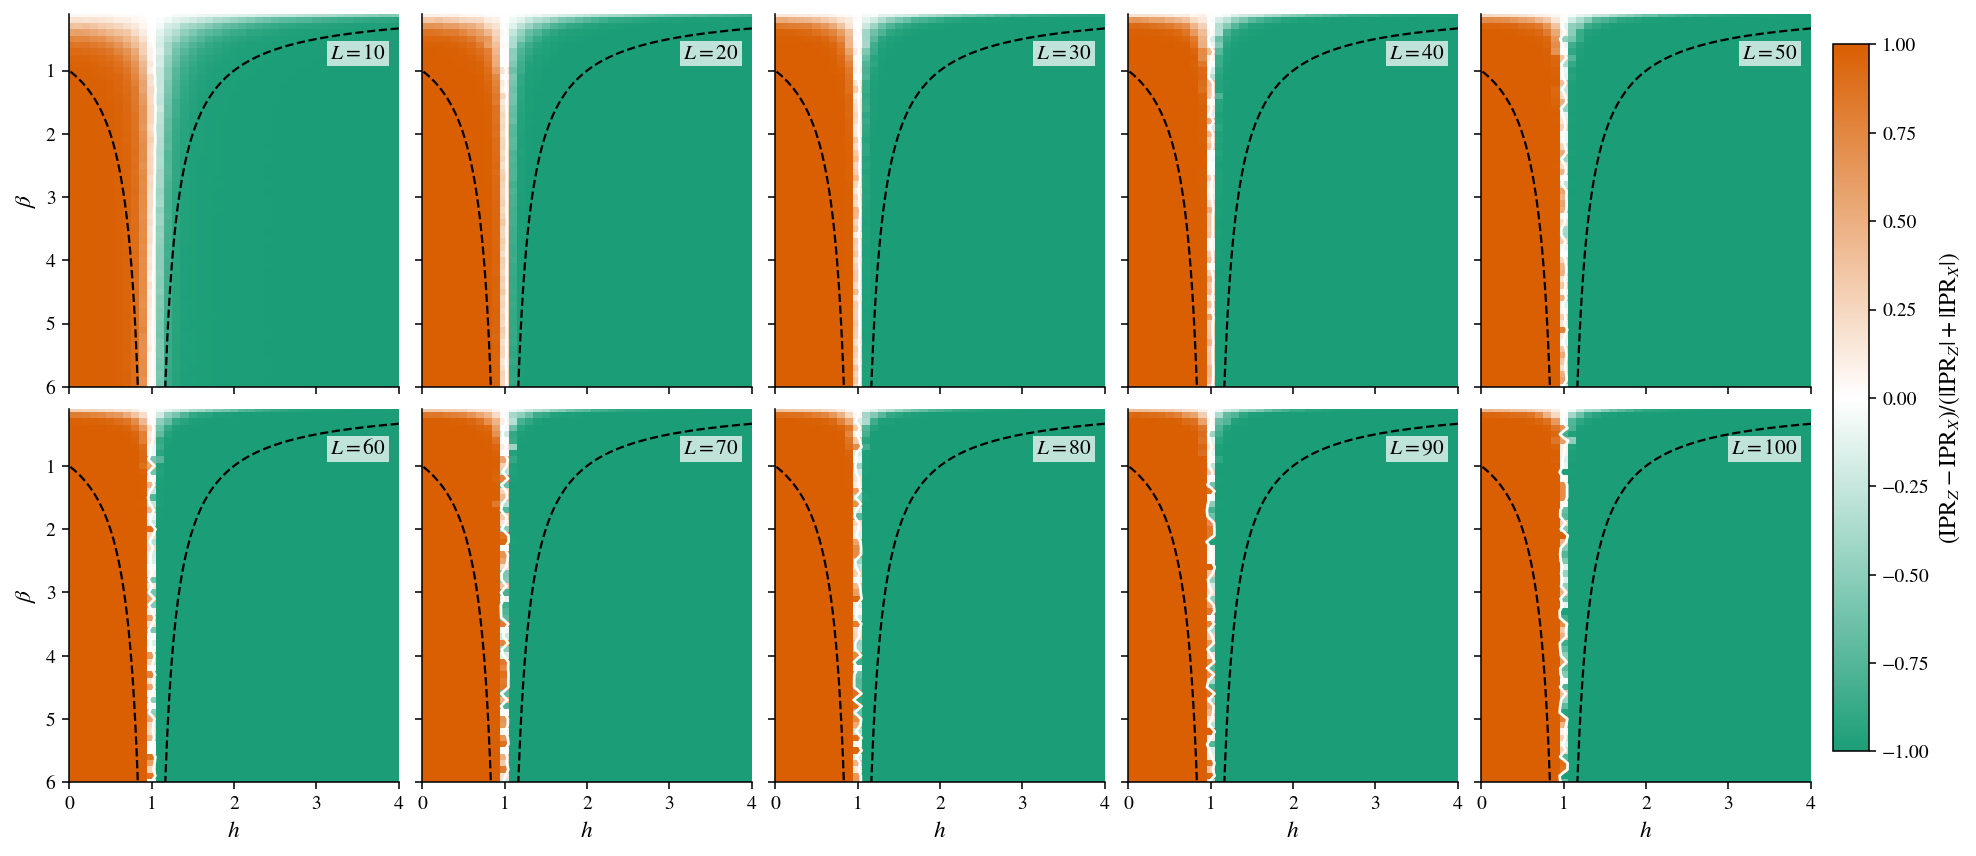

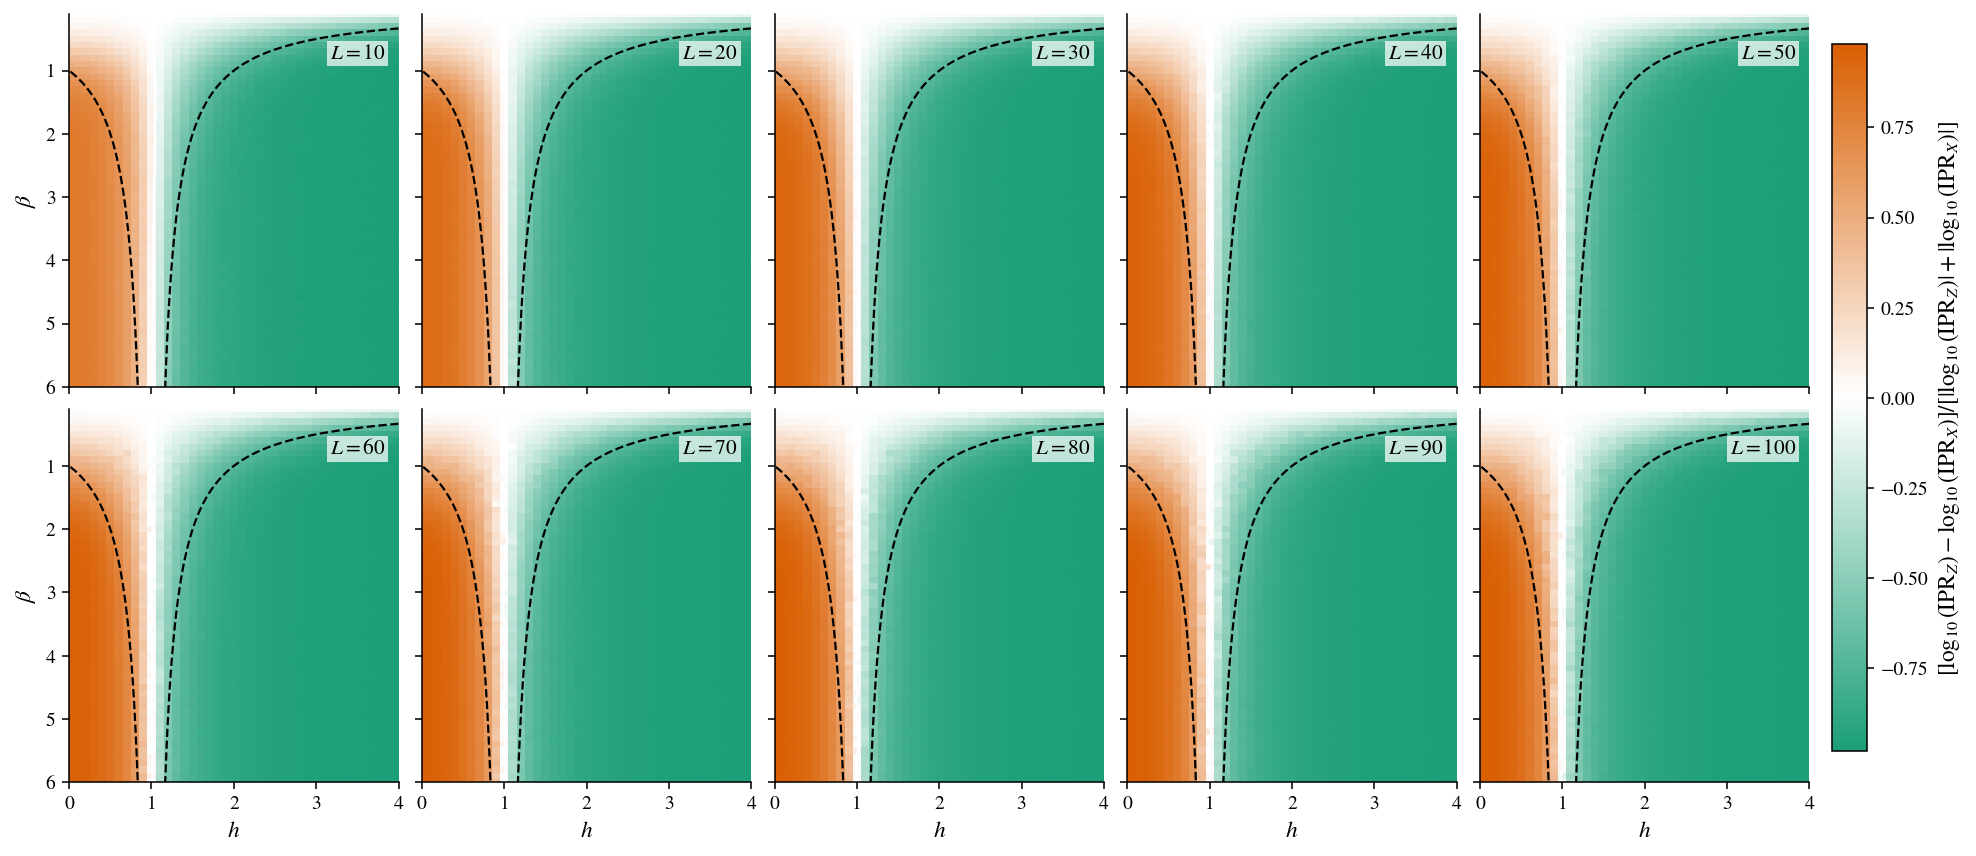

In [21]:
# Example: plot all selected raw thermal IPR system sizes together.
L_values = list(range(10, 101, 10))
beta_max = 6.0
save_figures = True
save_dir = Path("Paper plots Thermal")

raw_save_path = save_dir / "ipr_crossover_raw_beta_grid.png" if save_figures else None
fig, axes = plot_ipr_crossover_grid(
    L_values, source="raw", contrast="raw", hc=1.0, beta_max=beta_max,
    nrows=2, ncols=5, save_path=raw_save_path,
)
plt.show()

log_save_path = save_dir / "ipr_crossover_log_beta_grid.png" if save_figures else None
fig, axes = plot_ipr_crossover_grid(
    L_values, source="raw", contrast="log", hc=1.0, beta_max=beta_max,
    nrows=2, ncols=5, save_path=log_save_path,
)
plt.show()